# Домашнее задание 3: NER (FactRuEval-2016)

FactRuEval через `gusevski/factrueval2016`, RuBERT: baseline (метрики до/после NER), затем MLM обычный, whole-word и concept и псевдоразметка Ленты

### Обоснование

- **Энкодер** — `DeepPavlov/rubert-base-cased`: русский, cased, хорошо подходит к словам и FactRuEval; один бэкбон для всех экспериментов, чтобы сравнение было честным
- **Гиперпараметры** — `NER_LR=5e-5`, `NER_EPOCHS=5`, `MAX_LENGTH=256`, `BATCH_SIZE=16` — типичные значения для fine-tune BERT; MLM короче (2 эпохи), чтобы не «переписать» веса до NER
- **Teacher** — не DeepPavlov из примера в ТЗ, а `Babelscape/wikineural-multilingual-ner` в `pipeline("ner")` из HF: без отдельного сервера, мультиязычный NER, удобно для псевдоразметки; типы teacher (`PER`/`LOC`/`ORG`/…) маппятся в `TYPE_MAP` под метки FactRuEval


In [ ]:
# colab
! pip uninstall -y numpy pandas
! pip uninstall -y numpy
! pip install --no-cache-dir "numpy==2.0.2" "pandas==2.2.3"
! pip install "transformers==4.46.3" "accelerate==1.0.1" "sentencepiece==0.2.0" "seqeval==1.2.2" "corus" "razdel" "matplotlib"
! pip install "datasets==3.1.0"


In [2]:
import gc, os, random, subprocess, sys, warnings
from collections import Counter
from dataclasses import dataclass
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from corus import load_lenta
from datasets import Dataset, DatasetDict, concatenate_datasets, load_dataset
from razdel import tokenize as razdel_tokenize
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (
    AutoConfig, AutoModelForMaskedLM, AutoModelForTokenClassification, AutoTokenizer,
    DataCollatorForLanguageModeling, DataCollatorForTokenClassification, DataCollatorForWholeWordMask,
    PreTrainedTokenizerBase, Trainer, TrainingArguments, pipeline, set_seed as hf_set_seed,
)

warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")


'expandable_segments:True'

In [3]:
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

BASE_MODEL = "DeepPavlov/rubert-base-cased"

MAX_LENGTH = 256
BATCH_SIZE = 16
MLM_BATCH_SIZE = 8
MLM_GRAD_ACCUM = 2
NER_EPOCHS = 5
MLM_EPOCHS = 2
NER_LR = 5e-5
MLM_LR = 5e-5

OUTPUT_ROOT = "./runs"
os.makedirs(OUTPUT_ROOT, exist_ok=True)

GRAD_ACCUM = 2
EVAL_BATCH_SIZE = 16
DATALOADER_NUM_WORKERS = 0 if "google.colab" in sys.modules else 2
PIN_MEMORY = torch.cuda.is_available()

try:
    BF16 = torch.cuda.is_available() and bool(torch.cuda.is_bf16_supported())
except Exception:
    BF16 = False
FP16 = torch.cuda.is_available() and (not BF16)
GRADIENT_CHECKPOINTING = False

TEACHER_MODEL = "Babelscape/wikineural-multilingual-ner"
LENTA_N = 10000
LENTA_TEXT_MAX = 1500

mlm_std_path = os.path.join(OUTPUT_ROOT, "mlm_std_final")
mlm_wwm_path = os.path.join(OUTPUT_ROOT, "mlm_wwm_final")
mlm_concept_path = os.path.join(OUTPUT_ROOT, "mlm_concept_final")

def empty_device_cache():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    hf_set_seed(seed)


set_seed()
print("device:", DEVICE)
print("MAX_LENGTH:", MAX_LENGTH)



device: cuda
MAX_LENGTH: 256


In [4]:
print("torch", torch.__version__)
import transformers as _tf
print("transformers", _tf.__version__)
import datasets as _ds
print("datasets", _ds.__version__)


torch 2.10.0+cu128
transformers 4.46.3
datasets 3.1.0


## Данные

`gusevski/factrueval2016`: из сырых сплитов — плоские примеры «слова + BIO», словарь меток под классификатор.


In [5]:
raw = load_dataset("gusevski/factrueval2016")

def flatten_split(ds_split):
    rows = []
    for row in ds_split:
        for item in row["data"]:
            rows.append({"tokens": item["tokens"], "ner_tags": item["ner_tags_str"]})
    return rows

train_rows = flatten_split(raw["train"])
val_rows = flatten_split(raw["validation"])
test_rows = flatten_split(raw["test"])

label_set = sorted({t for r in train_rows for t in r["ner_tags"]})
label2id = {l: i for i, l in enumerate(label_set)}
id2label = {i: l for l, i in label2id.items()}
num_labels = len(label_set)

ds = DatasetDict(
    train=Dataset.from_list(train_rows),
    validation=Dataset.from_list(val_rows),
    test=Dataset.from_list(test_rows),
)
print(len(ds["train"]), len(ds["validation"]), len(ds["test"]), num_labels, label_set)


README.md: 0.00B [00:00, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train_data.json:   0%|          | 0.00/7.62M [00:00<?, ?B/s]

dev_data.json:   0%|          | 0.00/2.48M [00:00<?, ?B/s]

test_data.json:   0%|          | 0.00/2.57M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1 [00:00<?, ? examples/s]

7746 2582 2582 7 ['B-LOC', 'B-ORG', 'B-PER', 'I-LOC', 'I-ORG', 'I-PER', 'O']


## Токенизация и метки

По `word_ids`: метка только на первом субтокене слова, для хвоста слова и спецтокенов — `-100`. Метрики: `seqeval` (P/R/F1 по сущностям).


In [6]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

def tokenize_and_align_labels(examples):
    tok = tokenizer(
        examples["tokens"],
        is_split_into_words=True,
        truncation=True,
        max_length=MAX_LENGTH,
        padding=False,
    )
    labels = []
    for i, lab in enumerate(examples["ner_tags"]):
        wids = tok.word_ids(batch_index=i)
        label_ids = []
        prev_w = None
        for w in wids:
            if w is None:
                label_ids.append(-100)
            elif w != prev_w:
                label_ids.append(label2id[lab[w]])
            else:
                label_ids.append(-100)
            prev_w = w
        labels.append(label_ids)
    tok["labels"] = labels
    return tok

tokenized = ds.map(tokenize_and_align_labels, batched=True, remove_columns=ds["train"].column_names)


tokenizer_config.json:   0%|          | 0.00/24.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/7746 [00:00<?, ? examples/s]

Map:   0%|          | 0/2582 [00:00<?, ? examples/s]

Map:   0%|          | 0/2582 [00:00<?, ? examples/s]

`compute_metrics` + `seqeval`; строки в `results_log`. Коллатор с `label_pad_token_id=-100`.


In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    y_true, y_pred = [], []
    for p, l in zip(preds, labels):
        true_labels, pred_labels = [], []
        for pi, li in zip(p, l):
            if li == -100:
                continue
            true_labels.append(id2label[int(li)])
            pred_labels.append(id2label[int(pi)])
        y_true.append(true_labels)
        y_pred.append(pred_labels)
    return {
        "f1": float(f1_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred)),
        "recall": float(recall_score(y_true, y_pred)),
    }


def eval_to_result_row(method: str, split: str, ev: dict) -> dict:
    row = {"method": method, "split": split, "f1": ev["eval_f1"]}
    for k, v in ev.items():
        if not k.startswith("eval_f1_"):
            continue
        suffix = k[len("eval_f1_") :]
        if suffix:
            row[f"f1_{suffix}"] = float(v)
    return row


data_collator_ner = DataCollatorForTokenClassification(
    tokenizer, padding="longest", label_pad_token_id=-100
)


def load_mlm_model():
    cfg = AutoConfig.from_pretrained(BASE_MODEL)
    cfg.tie_word_embeddings = False
    return AutoModelForMaskedLM.from_pretrained(BASE_MODEL, config=cfg)


def pretrain_mlm(
    model_name_or_path,
    train_dataset,
    eval_dataset,
    run_name,
    collator,
    learning_rate=MLM_LR,
    num_train_epochs=MLM_EPOCHS,
    batch_size=MLM_BATCH_SIZE,
    save_dir=None,
):
    """MLM: eval каждую эпоху, лучший чекпоинт по eval_loss, затем освобождение GPU (del, gc, empty_cache)."""
    empty_device_cache()
    set_seed()
    out_dir = os.path.join(OUTPUT_ROOT, run_name)
    if save_dir is None:
        save_dir = out_dir

    if model_name_or_path == BASE_MODEL:
        model = load_mlm_model()
    else:
        model = AutoModelForMaskedLM.from_pretrained(model_name_or_path)

    args = TrainingArguments(
        output_dir=out_dir,
        evaluation_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="steps",
        logging_steps=100,
        learning_rate=learning_rate,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        num_train_epochs=num_train_epochs,
        weight_decay=0.01,
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        report_to="none",
        fp16=FP16,
        bf16=BF16,
        dataloader_num_workers=DATALOADER_NUM_WORKERS,
        dataloader_pin_memory=PIN_MEMORY,
        gradient_accumulation_steps=MLM_GRAD_ACCUM,
        gradient_checkpointing=True,
        seed=SEED,
        remove_unused_columns=False,
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        data_collator=collator,
        tokenizer=tokenizer,
    )
    trainer.evaluate()
    trainer.train()
    trainer.evaluate()

    trainer.save_model(save_dir)
    tokenizer.save_pretrained(save_dir)

    del model, trainer
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()



## Baseline NER

Оценка до fine-tune (случайная голова) и после обучения на train; чекпоинт и строки в `results_log`.


In [8]:
set_seed()
empty_device_cache()

def new_ner_model():
    return AutoModelForTokenClassification.from_pretrained(
        BASE_MODEL,
        num_labels=num_labels,
        id2label=id2label,
        label2id=label2id,
    )

model_baseline = new_ner_model()

args_eval = TrainingArguments(
    output_dir=os.path.join(OUTPUT_ROOT, "eval_tmp"),
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    do_train=False,
    do_eval=True,
    fp16=FP16,
    bf16=BF16,
    dataloader_num_workers=DATALOADER_NUM_WORKERS,
    dataloader_pin_memory=PIN_MEMORY,
    report_to=[],
)

trainer_eval = Trainer(
    model=model_baseline,
    args=args_eval,
    eval_dataset=tokenized["validation"],
    data_collator=data_collator_ner,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
m_before = trainer_eval.evaluate()
print("before_finetune_val", m_before)
del trainer_eval
empty_device_cache()


pytorch_model.bin:   0%|          | 0.00/714M [00:00<?, ?B/s]

Some weights of BertForTokenClassification were not initialized from the model checkpoint at DeepPavlov/rubert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


before_finetune_val {'eval_loss': 1.9806454181671143, 'eval_model_preparation_time': 0.0028, 'eval_f1': 0.034387333847479926, 'eval_precision': 0.019498893862221537, 'eval_recall': 0.1454336147352264, 'eval_runtime': 12.5323, 'eval_samples_per_second': 206.028, 'eval_steps_per_second': 12.927}


In [9]:
empty_device_cache()

args_ner = TrainingArguments(
    output_dir=os.path.join(OUTPUT_ROOT, "ner_baseline"),
    learning_rate=NER_LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    num_train_epochs=NER_EPOCHS,
    weight_decay=0.01,
    evaluation_strategy="epoch",
    save_strategy="no",
    load_best_model_at_end=False,
    report_to=[],
    fp16=FP16,
    bf16=BF16,
    dataloader_num_workers=DATALOADER_NUM_WORKERS,
    dataloader_pin_memory=PIN_MEMORY,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    seed=SEED,
)

trainer_ner = Trainer(
    model=model_baseline,
    args=args_ner,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=data_collator_ner,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
trainer_ner.train()
m_after_val = trainer_ner.evaluate(tokenized["validation"])
m_after_test = trainer_ner.evaluate(tokenized["test"])
print("after_finetune_val", m_after_val)
print("after_finetune_test", m_after_test)

_ner_dir = os.path.join(OUTPUT_ROOT, "ner_baseline_final")
trainer_ner.save_model(_ner_dir)
tokenizer.save_pretrained(_ner_dir)
results_log = [
    eval_to_result_row("baseline_before_finetune", "validation", m_before),
    eval_to_result_row("baseline_after_finetune", "validation", m_after_val),
    eval_to_result_row("baseline_after_finetune", "test", m_after_test),
]
del trainer_ner, model_baseline
empty_device_cache()


Epoch,Training Loss,Validation Loss,F1,Precision,Recall
0,No log,0.019331,0.973797,0.967253,0.980430
2,0.042800,0.016797,0.981476,0.981947,0.981005
4,0.004200,0.016632,0.984388,0.982788,0.985994


after_finetune_val {'eval_loss': 0.01663215644657612, 'eval_f1': 0.9843884685374964, 'eval_precision': 0.9827882960413081, 'eval_recall': 0.985993860322333, 'eval_runtime': 14.2203, 'eval_samples_per_second': 181.571, 'eval_steps_per_second': 11.392, 'epoch': 4.989690721649485}
after_finetune_test {'eval_loss': 0.01731427200138569, 'eval_f1': 0.984974046079592, 'eval_precision': 0.9838093505548481, 'eval_recall': 0.9861415025528811, 'eval_runtime': 14.2521, 'eval_samples_per_second': 181.166, 'eval_steps_per_second': 11.367, 'epoch': 4.989690721649485}


## MLM, затем NER

`text_for_mlm` для `mlm_tokenized`; MLM с лучшим чекпоинтом по `eval_loss`, затем NER с новой головой (`ignore_mismatched_sizes=True`). Дальше те же данные с WWM и concept-коллатором.


In [10]:
set_seed()


def join_tokens_for_mlm(batch):
    return {"text_for_mlm": [" ".join(t) for t in batch["tokens"]]}


mlm_raw = ds.map(join_tokens_for_mlm, batched=True)


def tokenize_for_mlm(examples):
    return tokenizer(
        examples["text_for_mlm"],
        truncation=True,
        max_length=MAX_LENGTH,
        return_special_tokens_mask=True,
    )


mlm_tokenized = mlm_raw.map(
    tokenize_for_mlm,
    batched=True,
    remove_columns=mlm_raw["train"].column_names,
)


Map:   0%|          | 0/7746 [00:00<?, ? examples/s]

Map:   0%|          | 0/2582 [00:00<?, ? examples/s]

Map:   0%|          | 0/2582 [00:00<?, ? examples/s]

Map:   0%|          | 0/7746 [00:00<?, ? examples/s]

Map:   0%|          | 0/2582 [00:00<?, ? examples/s]

Map:   0%|          | 0/2582 [00:00<?, ? examples/s]

In [11]:
collator_mlm_std = DataCollatorForLanguageModeling(
    tokenizer=tokenizer, mlm=True, mlm_probability=0.15
)
pretrain_mlm(
    BASE_MODEL,
    mlm_tokenized["train"],
    mlm_tokenized["validation"],
    "mlm_std",
    collator_mlm_std,
    save_dir=mlm_std_path,
)


BertForMaskedLM has generative capabilities, as `prepare_inputs_for_generation` is explicitly overwritten. However, it doesn't directly inherit from `GenerationMixin`. From 👉v4.50👈 onwards, `PreTrainedModel` will NOT inherit from `GenerationMixin`, and this model will lose the ability to call `generate` and other related functions.
  - If you're using `trust_remote_code=True`, you can get rid of this warning by loading the model with an auto class. See https://huggingface.co/docs/transformers/en/model_doc/auto#auto-classes
  - If you are the owner of the model architecture code, please modify your model class such that it inherits from `GenerationMixin` (after `PreTrainedModel`, otherwise you'll get an exception).
  - If you are not the owner of the model architecture class, please contact the model code owner to update it.


Epoch,Training Loss,Validation Loss,Model Preparation Time
0,1.755700,1.766507,0.003100
1,1.603500,1.695941,0.003100


There were missing keys in the checkpoint model loaded: ['cls.predictions.decoder.bias'].


In [12]:
set_seed()
model_ner_mlm = AutoModelForTokenClassification.from_pretrained(
    mlm_std_path,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

args_ner_mlm = TrainingArguments(
    output_dir=os.path.join(OUTPUT_ROOT, "ner_after_mlm_std"),
    learning_rate=NER_LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    num_train_epochs=NER_EPOCHS,
    weight_decay=0.01,
    evaluation_strategy="epoch",
    save_strategy="no",
    report_to=[],
    fp16=FP16,
    bf16=BF16,
    dataloader_num_workers=DATALOADER_NUM_WORKERS,
    dataloader_pin_memory=PIN_MEMORY,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    seed=SEED,
)

tr_ner_mlm = Trainer(
    model=model_ner_mlm,
    args=args_ner_mlm,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=data_collator_ner,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
tr_ner_mlm.train()
ev_mlm_val = tr_ner_mlm.evaluate(tokenized["validation"])
ev_mlm_test = tr_ner_mlm.evaluate(tokenized["test"])
print("ner_after_mlm_std", ev_mlm_val, ev_mlm_test)
results_log.append(eval_to_result_row("mlm_standard_then_ner", "validation", ev_mlm_val))
results_log.append(eval_to_result_row("mlm_standard_then_ner", "test", ev_mlm_test))


Some weights of BertForTokenClassification were not initialized from the model checkpoint at ./runs/mlm_std_final and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,F1,Precision,Recall
0,No log,0.023666,0.971117,0.968154,0.974098
2,0.041200,0.017207,0.980546,0.979514,0.981581
4,0.003900,0.020165,0.981237,0.979175,0.983308


ner_after_mlm_std {'eval_loss': 0.02016451396048069, 'eval_f1': 0.9812368370668197, 'eval_precision': 0.9791746274359954, 'eval_recall': 0.9833077513430545, 'eval_runtime': 13.0903, 'eval_samples_per_second': 197.245, 'eval_steps_per_second': 12.376, 'epoch': 4.989690721649485} {'eval_loss': 0.017915047705173492, 'eval_f1': 0.985710385000455, 'eval_precision': 0.9840087225149918, 'eval_recall': 0.987417943107221, 'eval_runtime': 13.4617, 'eval_samples_per_second': 191.803, 'eval_steps_per_second': 12.034, 'epoch': 4.989690721649485}


## Whole word masking

Те же `mlm_tokenized`, коллатор `DataCollatorForWholeWordMask`. В датасет `word_ids` не кладём — иначе конфликт с коллатором.


In [13]:
collator_wwm = DataCollatorForWholeWordMask(
    tokenizer=tokenizer, mlm=True, mlm_probability=0.15
)
pretrain_mlm(
    BASE_MODEL,
    mlm_tokenized["train"],
    mlm_tokenized["validation"],
    "mlm_wwm",
    collator_wwm,
    save_dir=mlm_wwm_path,
)


We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.


Epoch,Training Loss,Validation Loss,Model Preparation Time
0,1.991700,2.015528,0.002800
1,1.889300,1.914723,0.002800


There were missing keys in the checkpoint model loaded: ['cls.predictions.decoder.bias'].


In [14]:
set_seed()
model_ner_wwm = AutoModelForTokenClassification.from_pretrained(
    mlm_wwm_path,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

args_ner_wwm = TrainingArguments(
    output_dir=os.path.join(OUTPUT_ROOT, "ner_after_mlm_wwm"),
    learning_rate=NER_LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    num_train_epochs=NER_EPOCHS,
    weight_decay=0.01,
    evaluation_strategy="epoch",
    save_strategy="no",
    report_to=[],
    fp16=FP16,
    bf16=BF16,
    dataloader_num_workers=DATALOADER_NUM_WORKERS,
    dataloader_pin_memory=PIN_MEMORY,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    seed=SEED,
)

tr_ner_wwm = Trainer(
    model=model_ner_wwm,
    args=args_ner_wwm,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=data_collator_ner,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
tr_ner_wwm.train()
ev_wwm_val = tr_ner_wwm.evaluate(tokenized["validation"])
ev_wwm_test = tr_ner_wwm.evaluate(tokenized["test"])
print("ner_after_mlm_wwm", ev_wwm_val, ev_wwm_test)
results_log.append(eval_to_result_row("mlm_wwm_then_ner", "validation", ev_wwm_val))
results_log.append(eval_to_result_row("mlm_wwm_then_ner", "test", ev_wwm_test))


Some weights of BertForTokenClassification were not initialized from the model checkpoint at ./runs/mlm_wwm_final and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,F1,Precision,Recall
0,No log,0.021698,0.972989,0.971500,0.974482
2,0.041100,0.017218,0.980854,0.978793,0.982924
4,0.004000,0.019825,0.980464,0.978776,0.982157


ner_after_mlm_wwm {'eval_loss': 0.019825464114546776, 'eval_f1': 0.9804635127370236, 'eval_precision': 0.9787762906309752, 'eval_recall': 0.9821565617805065, 'eval_runtime': 13.0622, 'eval_samples_per_second': 197.669, 'eval_steps_per_second': 12.402, 'epoch': 4.989690721649485} {'eval_loss': 0.016630982980132103, 'eval_f1': 0.9850664724093972, 'eval_precision': 0.9838122953801383, 'eval_recall': 0.9863238512035011, 'eval_runtime': 13.434, 'eval_samples_per_second': 192.198, 'eval_steps_per_second': 12.059, 'epoch': 4.989690721649485}


## Concept masking

Повышенная вероятность маски на субтокенах внутри сущностей (не `O`), см. коллатор ниже.


In [21]:
@dataclass
class DataCollatorForConceptMLM:
    tokenizer: PreTrainedTokenizerBase
    mlm_probability: float = 0.15
    entity_mlm_probability: float = 0.45
    max_length: int = 256
    pad_to_multiple_of: int | None = None

    def __call__(self, examples: list[dict[str, Any]]) -> dict[str, Any]:
        tokens_batch = [ex["tokens"] for ex in examples]
        ner_batch = [ex["ner_tags"] for ex in examples]
        batch = self.tokenizer(
            tokens_batch,
            is_split_into_words=True,
            padding=True,
            truncation=True,
            max_length=self.max_length,
            return_special_tokens_mask=True,
            return_tensors="pt",
            pad_to_multiple_of=self.pad_to_multiple_of,
        )
        max_len = batch["input_ids"].shape[1]
        em_padded = []
        for i, ner_tags in enumerate(ner_batch):
            wids = batch.word_ids(batch_index=i)
            row = [
                0 if w is None else (1 if ner_tags[w] != "O" else 0) for w in wids
            ]
            if len(row) < max_len:
                row = row + [0] * (max_len - len(row))
            em_padded.append(row[:max_len])
        entity_tensor = torch.tensor(em_padded, dtype=torch.bool)
        special = batch.pop("special_tokens_mask", None)
        input_ids = batch["input_ids"]
        labels = input_ids.clone()
        prob = torch.full(labels.shape, self.mlm_probability)
        prob = torch.where(entity_tensor, torch.full_like(prob, self.entity_mlm_probability), prob)
        mask = torch.bernoulli(prob).bool()
        if special is not None:
            mask = mask & ~special.bool()
        labels[~mask] = -100
        random_replace = torch.bernoulli(torch.full(labels.shape, 0.8)).bool() & mask
        self_mask = mask & ~random_replace
        random_tokens = torch.randint(len(self.tokenizer), labels.shape, dtype=torch.long)
        input_ids = input_ids.clone()
        input_ids[random_replace] = random_tokens[random_replace]
        input_ids[self_mask] = self.tokenizer.mask_token_id
        batch["input_ids"] = input_ids
        batch["labels"] = labels
        return batch


In [22]:
set_seed()
collator_concept = DataCollatorForConceptMLM(
    tokenizer=tokenizer,
    mlm_probability=0.15,
    entity_mlm_probability=0.45,
    max_length=MAX_LENGTH,
)
pretrain_mlm(
    BASE_MODEL,
    ds["train"],
    ds["validation"],
    "mlm_concept",
    collator_concept,
    save_dir=mlm_concept_path,
)


Epoch,Training Loss,Validation Loss,Model Preparation Time
0,2.853300,2.788851,0.004900
1,2.468200,2.623727,0.004900


There were missing keys in the checkpoint model loaded: ['cls.predictions.decoder.bias'].


In [23]:
set_seed()
model_ner_concept = AutoModelForTokenClassification.from_pretrained(
    mlm_concept_path,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
)

args_ner_concept = TrainingArguments(
    output_dir=os.path.join(OUTPUT_ROOT, "ner_after_mlm_concept"),
    learning_rate=NER_LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    num_train_epochs=NER_EPOCHS,
    weight_decay=0.01,
    evaluation_strategy="epoch",
    save_strategy="no",
    report_to=[],
    fp16=FP16,
    bf16=BF16,
    dataloader_num_workers=DATALOADER_NUM_WORKERS,
    dataloader_pin_memory=PIN_MEMORY,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    seed=SEED,
)

tr_ner_concept = Trainer(
    model=model_ner_concept,
    args=args_ner_concept,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=data_collator_ner,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
tr_ner_concept.train()
ev_c_val = tr_ner_concept.evaluate(tokenized["validation"])
ev_c_test = tr_ner_concept.evaluate(tokenized["test"])
print("ner_after_mlm_concept", ev_c_val, ev_c_test)
results_log.append(eval_to_result_row("mlm_concept_then_ner", "validation", ev_c_val))
results_log.append(eval_to_result_row("mlm_concept_then_ner", "test", ev_c_test))


Some weights of BertForTokenClassification were not initialized from the model checkpoint at ./runs/mlm_concept_final and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,F1,Precision,Recall
0,No log,0.020243,0.969866,0.970238,0.969493
2,0.042800,0.018268,0.980854,0.978793,0.982924
4,0.004200,0.019857,0.981529,0.979187,0.983883


ner_after_mlm_concept {'eval_loss': 0.01985718309879303, 'eval_f1': 0.9815293329505215, 'eval_precision': 0.9791865571892304, 'eval_recall': 0.9838833461243285, 'eval_runtime': 13.0604, 'eval_samples_per_second': 197.697, 'eval_steps_per_second': 12.404, 'epoch': 4.989690721649485} {'eval_loss': 0.018277328461408615, 'eval_f1': 0.9844531321029184, 'eval_precision': 0.9816863100634633, 'eval_recall': 0.987235594456601, 'eval_runtime': 13.4442, 'eval_samples_per_second': 192.052, 'eval_steps_per_second': 12.05, 'epoch': 4.989690721649485}


## Псевдоразметка Ленты

~10k текстов (`LENTA_N`), teacher — `Babelscape/wikineural-multilingual-ner`. Сущности из pipeline (`entity_group`) приводятся к нашим типам через **`TYPE_MAP`** (например `PER`→`PER`); остальное отбрасывается. Псевдо-BIO и train **конкатенируются** без взвешивания — см. код в ячейке ниже


In [24]:
DATA_PATH = "lenta-ru-news.csv.gz"
DATA_URL = (
    "https://github.com/yutkin/Lenta.Ru-News-Dataset/releases/download/v1.0/lenta-ru-news.csv.gz"
)
if not os.path.exists(DATA_PATH) or os.path.getsize(DATA_PATH) < 80_000_000:
    subprocess.run(["curl", "-L", "-o", DATA_PATH, DATA_URL], check=True)

TYPE_MAP = {"PER": "PER", "LOC": "LOC", "ORG": "ORG"}

def lenta_texts_to_pseudo(n=LENTA_N):
    rows = []
    for i, rec in enumerate(load_lenta(DATA_PATH)):
        if i >= n:
            break
        text = " ".join((rec.title + " " + rec.text).split())
        text = text[:LENTA_TEXT_MAX]
        if len(text) < 20:
            continue
        rows.append(text)
    return rows

lenta_texts = lenta_texts_to_pseudo()
print("lenta_sample", len(lenta_texts))


lenta_sample 10000


In [25]:
set_seed()
ner_teacher = pipeline(
    "ner",
    model=TEACHER_MODEL,
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1,
)

def words_bio_from_text(text):
    ents = ner_teacher(text)
    words = list(razdel_tokenize(text))
    tags = ["O"] * len(words)
    for e in ents:
        typ = TYPE_MAP.get(e.get("entity_group") or e.get("entity"))
        if typ is None:
            continue
        es, ee = int(e["start"]), int(e["end"])
        hit = [j for j, w in enumerate(words) if not (w.stop <= es or w.start >= ee)]
        for k, j in enumerate(hit):
            tags[j] = f"B-{typ}" if k == 0 else f"I-{typ}"
    toks = [w.text for w in words]
    return {"tokens": toks, "ner_tags": tags}

pseudo_rows = []
dropped_by_type = Counter()
for t in lenta_texts:
    try:
        pseudo_rows.append(words_bio_from_text(t))
    except Exception as e:
        dropped_by_type[type(e).__name__] += 1

n_in = len(lenta_texts)
n_ok = len(pseudo_rows)
print(
    f"pseudo_ok={n_ok} dropped={n_in - n_ok} of {n_in} "
    f"by_error_type={dict(dropped_by_type)}"
)
pseudo_ds = Dataset.from_list(pseudo_rows)
train_mixed = concatenate_datasets([ds["train"], pseudo_ds])
tokenized_mixed = train_mixed.map(tokenize_and_align_labels, batched=True, remove_columns=train_mixed.column_names)


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/709M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/333 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 9b8f7954-0d00-4095-b92f-7dbc6d1b4a78)')' thrown while requesting HEAD https://huggingface.co/Babelscape/wikineural-multilingual-ner/resolve/main/added_tokens.json
Retrying in 1s [Retry 1/5].


special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


pseudo_ok=10000 dropped=0 of 10000 by_error_type={}


Map:   0%|          | 0/17746 [00:00<?, ? examples/s]

In [26]:
set_seed()
model_pseudo = new_ner_model()

args_ner_mix = TrainingArguments(
    output_dir=os.path.join(OUTPUT_ROOT, "ner_mixed_pseudo"),
    learning_rate=NER_LR,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    num_train_epochs=NER_EPOCHS,
    weight_decay=0.01,
    evaluation_strategy="epoch",
    save_strategy="no",
    report_to=[],
    fp16=FP16,
    bf16=BF16,
    dataloader_num_workers=DATALOADER_NUM_WORKERS,
    dataloader_pin_memory=PIN_MEMORY,
    gradient_accumulation_steps=GRAD_ACCUM,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    seed=SEED,
)

tr_mix = Trainer(
    model=model_pseudo,
    args=args_ner_mix,
    train_dataset=tokenized_mixed,
    eval_dataset=tokenized["validation"],
    data_collator=data_collator_ner,
    tokenizer=tokenizer,
    compute_metrics=compute_metrics,
)
tr_mix.train()
ev_mix_val = tr_mix.evaluate(tokenized["validation"])
ev_mix_test = tr_mix.evaluate(tokenized["test"])
print("ner_train_plus_pseudo", ev_mix_val, ev_mix_test)
results_log.append(eval_to_result_row("baseline_ner_plus_lenta_pseudo", "validation", ev_mix_val))
results_log.append(eval_to_result_row("baseline_ner_plus_lenta_pseudo", "test", ev_mix_test))


Some weights of BertForTokenClassification were not initialized from the model checkpoint at DeepPavlov/rubert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,F1,Precision,Recall
1,0.052400,0.023781,0.955403,0.949072,0.961819
2,0.022300,0.018929,0.968149,0.965287,0.971028
3,0.015500,0.018581,0.975245,0.975432,0.975058
4,0.011400,0.022076,0.977850,0.977382,0.978319
5,0.007800,0.022909,0.978842,0.976878,0.980814


ner_train_plus_pseudo {'eval_loss': 0.022909224033355713, 'eval_f1': 0.9788415509813307, 'eval_precision': 0.9768775081215364, 'eval_recall': 0.9808135072908672, 'eval_runtime': 13.8013, 'eval_samples_per_second': 187.083, 'eval_steps_per_second': 11.738, 'epoch': 5.0} {'eval_loss': 0.023821573704481125, 'eval_f1': 0.9736315693762502, 'eval_precision': 0.9709829524845847, 'eval_recall': 0.9762946754194018, 'eval_runtime': 14.2389, 'eval_samples_per_second': 181.334, 'eval_steps_per_second': 11.377, 'epoch': 5.0}


## Сводка

`DataFrame` по `results_log`, график overall F1, `results_summary.csv`. Если в `compute_metrics` есть per-entity F1 — дополнительно печатается блок **Per-entity F1 (test)** и `results_per_entity_f1_test.csv`


split                               test  validation
method                                              
baseline_after_finetune         0.984974    0.984388
baseline_before_finetune             NaN    0.034387
baseline_ner_plus_lenta_pseudo  0.973632    0.978842
mlm_concept_then_ner            0.984453    0.981529
mlm_standard_then_ner           0.985710    0.981237
mlm_wwm_then_ner                0.985066    0.980464


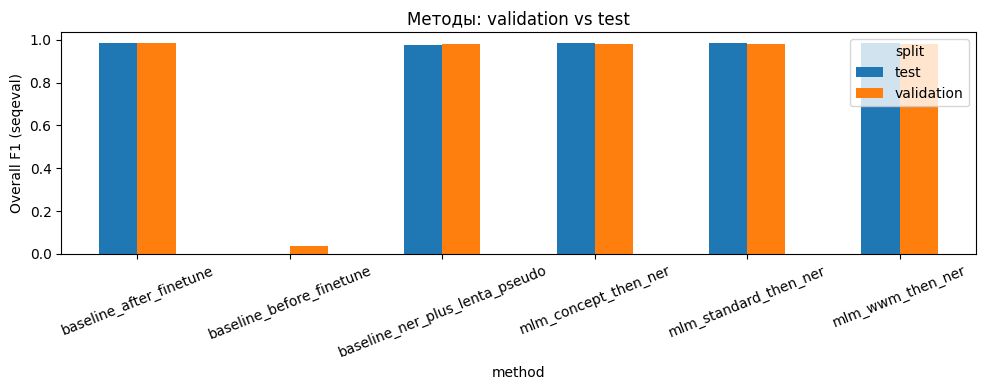

In [27]:
summary = pd.DataFrame(results_log)
pivot = summary.pivot_table(index="method", columns="split", values="f1")
print(pivot)

fig, ax = plt.subplots(figsize=(10, 4))
pivot.plot(kind="bar", ax=ax, rot=22)
ax.set_ylabel("Overall F1 (seqeval)")
ax.set_title("Методы: validation vs test")
ax.legend(title="split")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "results_f1_bar.png"), dpi=120)
plt.show()

summary.to_csv(os.path.join(OUTPUT_ROOT, "results_summary.csv"), index=False)

entity_cols = [c for c in summary.columns if c.startswith("f1_")]
if entity_cols:
    print("\nPer-entity F1 (test):")
    test_ent = summary[summary["split"] == "test"].set_index("method")[entity_cols]
    print(test_ent)
    test_ent.to_csv(os.path.join(OUTPUT_ROOT, "results_per_entity_f1_test.csv"))


## Выводы

| Метод | Val F1 | Test F1 |
|------|--------|---------|
| baseline (после NER) | 0,984 | 0,985 |
| MLM standard → NER | 0,981 | **0,986** |
| MLM WWM → NER | 0,980 | 0,985 |
| MLM concept → NER | 0,982 | 0,984 |
| train + псевдо Лента | 0,979 | 0,974 |

**До/после** — без fine-tune F1 ≈ 0,034; после NER: val **0,984**, test **0,985**, P и R ~**0,983–0,986**

**MLM** — на test лучше **обычный** MLM; WWM и concept около baseline; на val у MLM чуть ниже baseline

**Лента** — хуже baseline; вероятно домен новостей и шум teacher

**Дальше** — смотреть per-entity F1 в сводке (после перезапуска ячеек с обучением), уменьшать долю псевдоданных или фильтровать по уверенности
